# Figure 2 – Combined Figure

This notebook builds the full Figure 2 layout directly from data (no image stitching).


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

# Ensure code_repository/notebooks is importable
HERE = Path.cwd().resolve()
if (HERE / "notebooks").exists():
    SRC_ROOT = HERE / "notebooks"
elif (HERE / "code_repository" / "notebooks").exists():
    SRC_ROOT = HERE / "code_repository" / "notebooks"
elif (HERE.parent / "code_repository" / "notebooks").exists():
    SRC_ROOT = HERE.parent / "code_repository" / "notebooks"
else:
    SRC_ROOT = None
if SRC_ROOT is not None:
    sys.path.insert(0, str(SRC_ROOT))


from pathlib import Path
from collections import Counter
import math
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, FormatStrFormatter

from analysis.plot_style import apply_style, style_axes, save_figure, set_save_dir
from data_processing.chemistry import prepare_compound_data_from_excels

apply_style()

ROOT = Path.cwd().resolve()
if (ROOT / 'Data').exists():
    PROJECT_ROOT = ROOT
elif (ROOT.parent / 'Data').exists():
    PROJECT_ROOT = ROOT.parent
else:
    PROJECT_ROOT = ROOT

# Fixed MoA order and palette
MOA_ORDER_FIXED = [
    'Fatty acid',
    'Nitrofurans',
    'Folic acid',
    'Membrane',
    'RNA synth.',
    'LPS synth.',
    'DNA repl.',
    'Cell wall',
    'Protein syn.',
]
COLORS = [
    '#264653', '#287271', '#2a9d8f', '#7fb48a',
    '#e9c46a', '#c6902e', '#f28e2b', '#e76f51', '#d1495b',
]
MOA_COLOR_MAP = {m: COLORS[i] for i, m in enumerate(MOA_ORDER_FIXED)}

def short_moa(s: str) -> str:
    mapping = {
        'DNA replication': 'DNA repl.',
        'Cell wall biosynthesis': 'Cell wall',
        'Protein synthesis': 'Protein syn.',
        'Membrane disruption': 'Membrane',
        'Folic acid metabolism': 'Folic acid',
        'lipopolysaccharide synthesis': 'LPS synth.',
        'Fatty acid synthesis': 'Fatty acid',
        'RNA Synthesis': 'RNA synth.',
        'Nitrofurans': 'Nitrofurans',
    }
    return mapping.get(str(s), str(s))

def moa_palette(moa_order: list[str]) -> dict[str, str]:
    return {m: MOA_COLOR_MAP.get(m, '#bdbdbd') for m in moa_order}


2026-02-24 12:30:08.212578: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1771936208.225257    6860 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1771936208.229107    6860 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1771936208.240247    6860 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771936208.240261    6860 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771936208.240263    6860 computation_placer.cc:177] computation placer alr

In [6]:
# --- Load core data ---
mic_data = pd.read_pickle(PROJECT_ROOT / 'Data' / 'Base' / 'X_mic.pkl')
ecfp_data = pd.read_pickle(PROJECT_ROOT / 'Data' / 'Base' / 'X_ecfp.pkl')
y_labels = pd.read_pickle(PROJECT_ROOT / 'Data' / 'Base' / 'y_labels.pkl')
proteomics_data = pd.read_pickle(PROJECT_ROOT / 'Data' / 'Base' / 'X_proteomics.pkl')

ecfp_unique = ecfp_data.drop_duplicates()

# --- Growth curves (compound sheets) ---
compound_data_folder = PROJECT_ROOT / 'Data' 
compound_dict = prepare_compound_data_from_excels(
    growth_curve_file=compound_data_folder / '250808_compounds.xlsx',
    mic_file=compound_data_folder / '250808_compounds.xlsx',
    smiles_file=compound_data_folder / '250808_compounds.xlsx',
    output_pickle_path=None,
)


{'Ampicillin (sodium)': 'JH0', 'Amoxicillin': 'JH1', 'Sulopenem': 'JH2', 'Cefodizime': 'JH3', 'Aztreonam': 'JH4', 'Doripenem': 'JH5', 'Imipenem (monohydrate)': 'JH6', 'Ertapenem (disodium)': 'JH7', 'Cefiderocol': 'JH8', 'Cefepime': 'JH9', 'Fosfomycin (calcium)': 'JH10', 'Retapamulin': 'JH11', 'Framycetin (sulfate)': 'JH12', 'Chloramphenicol': 'JH13', 'Tigecycline': 'JH14', 'Tetracycline': 'JH15', 'Azithromycin': 'JH16', 'Gentamicin sulfate': 'JH17', 'Eravacycline (dihydrochloride)': 'JH18', 'Apramycin (sulfate)': 'JH19', 'Kanamycin sulfate': 'JH55', 'Tobramycine': 'JH56', 'Sulfamonomethoxine': 'JH20', 'Sulfisoxazole': 'JH21', 'Sulfacetamide': 'JH22', 'Trimethoprim': 'JH23', 'Tetroxoprim': 'JH24', 'Sulfaguanidine': 'JH25', 'Sulphanilamide': 'JH57', 'Sulfadiazine': 'JH63', 'Gatifloxacin': 'JH26', 'Temafloxacin': 'JH27', 'Lascufloxacin': 'JH28', 'Ciprofloxacin': 'JH29', 'Levofloxacin': 'JH30', 'Nitrofurantoin': 'JH31', 'Gepotidacin': 'JH32', 'Nalidixic acid': 'JH33', 'Novobiocin': 'JH34',

In [7]:
# --- Helper functions (MIC, embeddings, growth curves) ---

def _labels_to_series(y_labels: pd.Series | pd.DataFrame, label_col: str | None) -> pd.Series:
    if isinstance(y_labels, pd.DataFrame):
        if label_col is None:
            for cand in ['mode_of_action', 'moa', 'label', 'y']:
                if cand in y_labels.columns:
                    label_col = cand
                    break
        if label_col is None:
            raise ValueError('Set label_col to the MoA column in y_labels.')
        return y_labels[label_col].astype(str)
    return y_labels.astype(str)

def compute_mic_from_matrix(mic_df: pd.DataFrame, thresh: float = 0.1) -> pd.Series:
    conc = pd.Index([float(c) for c in mic_df.columns], name='concentration')
    df = mic_df.copy()
    df.columns = conc
    df = df.loc[:, sorted(df.columns)]
    df = df.drop_duplicates()

    def row_mic(series: pd.Series, thresh: float) -> float | None:
        s = pd.to_numeric(series, errors='coerce')
        mask = s < thresh
        if mask.any():
            first_idx = np.flatnonzero(mask.values)[0]
            return float(s.index[first_idx])
        return np.nan

    return df.apply(row_mic, axis=1, thresh=thresh)

def plot_mic_by_moa_violin_ax(
    ax,
    mic_data: pd.DataFrame,
    y_labels: pd.Series | pd.DataFrame,
    ecfp_unique: pd.DataFrame | None = None,
    label_col: str | None = None,
    thresh: float = 0.1,
    bw_adjust: float = 1.15,
    cut: float = 0.2,
):
    mic_series = compute_mic_from_matrix(mic_data, thresh=thresh).rename('MIC')
    y_series = _labels_to_series(y_labels, label_col)

    idx = mic_series.index.intersection(y_series.index)
    if ecfp_unique is not None:
        idx = idx.intersection(ecfp_unique.index)

    dfp = pd.DataFrame({'MIC': mic_series.loc[idx], 'MoA': y_series.loc[idx]})
    dfp = dfp.dropna(subset=['MIC'])
    dfp['MoA_short'] = dfp['MoA'].map(short_moa)
    dfp = dfp[dfp['MIC'] > 0].copy()
    dfp['MIC_log10'] = np.log10(dfp['MIC'])

    moa_order = [m for m in MOA_ORDER_FIXED if m in dfp['MoA_short'].unique()]
    pal = moa_palette(moa_order)

    ymin = np.floor(dfp['MIC_log10'].min())
    ymax = np.ceil(dfp['MIC_log10'].max())
    major_ticks = np.arange(ymin, ymax + 1)

    sns.violinplot(
        data=dfp,
        x='MoA_short',
        y='MIC_log10',
        order=moa_order,
        palette=[pal[m] for m in moa_order],
        inner=None,
        cut=cut,
        scale='width',
        bw_adjust=bw_adjust,
        linewidth=0.8,
        ax=ax,
        zorder=1,
    )

    sns.swarmplot(
        data=dfp,
        x='MoA_short',
        y='MIC_log10',
        order=moa_order,
        dodge=False,
        facecolor='white',
        edgecolor='black',
        linewidth=0.5,
        alpha=0.95,
        size=3.0,
        ax=ax,
        zorder=3,
    )

    ax.set_xlabel('')
    ax.set_ylabel('MIC [µM]')
    ax.set_title('')
    ax.set_yticks(major_ticks)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'$10^{{{int(v):d}}}$'))
    ax.set_ylim(major_ticks.min(), major_ticks.max())
    ax.grid(True, axis='y', alpha=0.3)
    ax.tick_params(axis='x', which='both', labelbottom=False)
    ax.set_xticks([])
    style_axes(ax)
    return dfp

def plot_ecfp_embedding_ax(
    ax,
    ecfp_unique: pd.DataFrame,
    y_labels: pd.Series | pd.DataFrame,
    label_col: str | None = None,
    use_umap: bool = True,
    draw_hulls: bool = True,
):
    y_series = _labels_to_series(y_labels, label_col)
    common_idx = ecfp_unique.index.intersection(y_series.index)
    X = np.asarray(ecfp_unique.loc[common_idx], dtype=float)
    y = y_series.loc[common_idx].map(short_moa)

    if X.size == 0:
        raise ValueError('No overlap between ecfp_unique and y_labels after alignment.')

    method = 'UMAP'
    try:
        if use_umap:
            import umap
            reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
            emb = reducer.fit_transform(X)
        else:
            raise ImportError
    except Exception:
        from sklearn.decomposition import PCA
        pca = PCA(n_components=2, random_state=42)
        emb = pca.fit_transform(X)
        method = 'PCA'

    plot_df = pd.DataFrame(emb, columns=[f'{method}1', f'{method}2'], index=common_idx)
    plot_df['MoA'] = y.values

    counts = Counter(plot_df['MoA'])
    moa_order = [m for m, _ in sorted(counts.items(), key=lambda x: x[1], reverse=True)]
    pal = moa_palette(moa_order)

    try:
        from scipy.spatial import ConvexHull
        has_scipy = True
    except Exception:
        has_scipy = False

    def draw_convex_hull(ax, x, y, color, alpha=0.08, lw=0.7):
        if (not has_scipy) or len(x) < 3:
            return
        pts = np.column_stack([x, y])
        try:
            hull = ConvexHull(pts)
            poly = pts[hull.vertices]
            ax.fill(poly[:, 0], poly[:, 1], color=color, alpha=alpha, edgecolor='none')
            ax.plot(poly[:, 0], poly[:, 1], color=color, lw=lw, alpha=alpha * 1.5)
        except Exception:
            pass

    if draw_hulls:
        for moa in moa_order:
            sub = plot_df.loc[plot_df['MoA'] == moa]
            draw_convex_hull(
                ax,
                sub[f'{method}1'].values,
                sub[f'{method}2'].values,
                pal[moa],
            )

    for moa in moa_order:
        sub = plot_df.loc[plot_df['MoA'] == moa]
        ax.scatter(
            sub[f'{method}1'],
            sub[f'{method}2'],
            s=28,
            c=[pal[moa]],
            edgecolors='white',
            linewidths=0.5,
            alpha=0.95,
        )

    ax.set_xlabel(f'{method}1')
    ax.set_ylabel(f'{method}2')
    ax.set_title('')
    ax.grid(True, linestyle=':', alpha=0.3)
    ax.margins(x=0.05, y=0.05)
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    style_axes(ax)
    return plot_df

def _base_compound_id(idx: pd.Index) -> pd.Index:
    def strip(x: str) -> str:
        m = re.match(r'^(.*)_(\d+)$', str(x))
        return m.group(1) if m else str(x)
    return pd.Index([strip(i) for i in idx], name='compound')

def plot_proteomics_embedding_ax(
    ax,
    proteomics_data: pd.DataFrame,
    y_labels: pd.Series | pd.DataFrame,
    label_col: str | None = None,
    replicate_mode: str = 'all',
    use_umap: bool = True,
    draw_hulls: bool = True,
    random_state: int = 42,
):
    if isinstance(y_labels, pd.DataFrame):
        if label_col is None:
            for cand in ['mode_of_action', 'moa', 'label', 'y']:
                if cand in y_labels.columns:
                    label_col = cand
                    break
            if label_col is None:
                raise ValueError('Set label_col to the MoA column in y_labels.')
        y_series = y_labels[label_col].astype(str)
    else:
        y_series = y_labels.astype(str)

    compounds = _base_compound_id(proteomics_data.index)
    X = proteomics_data.copy()
    X.insert(0, '_compound', compounds)

    if replicate_mode == 'median':
        Xg = X.groupby('_compound').median(numeric_only=True)
        y_comp = _base_compound_id(y_series.index)
        y_series2 = pd.Series(y_series.values, index=y_comp, name=y_series.name)
        y_mode = y_series2.groupby(level=0).agg(lambda s: s.mode().iloc[0] if not s.mode().empty else s.iloc[0])
        common = Xg.index.intersection(y_mode.index)
        X_mat = Xg.loc[common]
        y_vec = y_mode.loc[common]
        marker_alpha = 0.95
        marker_size = 28
    elif replicate_mode == 'first':
        first_rows = X.groupby('_compound').head(1).set_index('_compound')
        y_comp = _base_compound_id(y_series.index)
        y_series2 = pd.Series(y_series.values, index=y_comp, name=y_series.name)
        common = first_rows.index.intersection(y_series2.index)
        X_mat = first_rows.loc[common]
        y_vec = y_series2.loc[common]
        marker_alpha = 0.95
        marker_size = 28
    else:
        y_series2 = y_series.reindex(proteomics_data.index)
        X_mat = proteomics_data.loc[y_series2.index]
        y_vec = y_series2
        marker_alpha = 0.8
        marker_size = 22

    from sklearn.preprocessing import StandardScaler
    scaler = StandardScaler(with_mean=True, with_std=True)
    X_scaled = scaler.fit_transform(np.asarray(X_mat, dtype=float))

    method = 'UMAP'
    try:
        if use_umap:
            import umap
            reducer = umap.UMAP(n_neighbors=50, min_dist=0.5, random_state=random_state, metric='euclidean')
            emb = reducer.fit_transform(X_scaled)
        else:
            raise ImportError
    except Exception:
        from sklearn.decomposition import PCA
        reducer = PCA(n_components=2, random_state=random_state)
        emb = reducer.fit_transform(X_scaled)
        method = 'PCA'

    plot_df = pd.DataFrame(emb, columns=[f'{method}1', f'{method}2'], index=X_mat.index)
    plot_df['MoA'] = y_vec.values
    plot_df['MoA_short'] = plot_df['MoA'].map(short_moa)

    counts = Counter(plot_df['MoA_short'])
    moa_order = [m for m, _ in sorted(counts.items(), key=lambda x: x[1], reverse=True)]
    pal = moa_palette(moa_order)

    try:
        from scipy.spatial import ConvexHull
        has_scipy = True
    except Exception:
        has_scipy = False

    def draw_convex_hull(ax, x, y, color, alpha=0.08, lw=0.7):
        if (not has_scipy) or len(x) < 3:
            return
        pts = np.column_stack([x, y])
        try:
            hull = ConvexHull(pts)
            poly = pts[hull.vertices]
            ax.fill(poly[:, 0], poly[:, 1], color=color, alpha=alpha, edgecolor='none')
            ax.plot(poly[:, 0], poly[:, 1], color=color, lw=lw, alpha=alpha * 1.5)
        except Exception:
            pass

    if draw_hulls:
        for moa in moa_order:
            sub = plot_df.loc[plot_df['MoA_short'] == moa]
            draw_convex_hull(ax, sub[f'{method}1'].values, sub[f'{method}2'].values, pal[moa])

    for moa in moa_order:
        sub = plot_df.loc[plot_df['MoA_short'] == moa]
        ax.scatter(
            sub[f'{method}1'],
            sub[f'{method}2'],
            s=marker_size,
            c=[pal[moa]],
            edgecolors='white',
            linewidths=0.5,
            alpha=marker_alpha,
            zorder=3,
        )

    ax.set_xlabel(f'{method}1')
    ax.set_ylabel(f'{method}2')
    ax.set_title('')
    ax.grid(True, linestyle=':', alpha=0.3)
    ax.margins(x=0.05, y=0.05)
    style_axes(ax)
    return plot_df

# --- Growth curve cleaning ---
TARGET_MULTIPLES = np.array([1, 5, 10, 15, 20, 50, 100], dtype=float)
TIMEPOINTS_H = [0, 1, 2, 3, 4, 5, 6, 7, 8, 24]

def _normalize_condition_label(label: str) -> str:
    if label is None:
        return ''
    s = str(label).strip()
    s = s.replace(',', '.')
    s = re.sub(r'\s+', '', s)
    s = re.sub(r'(?i)mmic', 'MIC', s)
    s = re.sub(r'(?i)xmic$', 'xMIC', s)
    return s

def _is_dmso(label: str) -> bool:
    s = str(label).strip().lower()
    return s in {'dmso', 'vehicle', 'control'}

def _extract_multiple(label: str) -> float | None:
    if not label:
        return None
    m = re.search(r'(?i)^\s*([0-9]*\.?[0-9]+)\s*x\s*MIC\s*$', label)
    if m:
        try:
            return float(m.group(1))
        except ValueError:
            return None
    return None

def _bucket_multiple(x: float) -> float:
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.nan
    diffs = np.abs(TARGET_MULTIPLES - float(x))
    idxs = np.where(diffs == diffs.min())[0]
    return float(TARGET_MULTIPLES[idxs.max()])

def _clean_one_growth_table_firstcol_condition(growth_df: pd.DataFrame) -> pd.DataFrame:
    if growth_df.shape[1] < 11:
        raise ValueError('Expected at least 11 columns (1 condition + 10 timepoints).')

    cond = growth_df.iloc[:, 0].astype(str).map(_normalize_condition_label)
    num = growth_df.iloc[:, 1:11].apply(pd.to_numeric, errors='coerce')

    rename_map = {num.columns[i]: TIMEPOINTS_H[i] for i in range(10)}
    num = num.rename(columns=rename_map)

    df_long = (
        pd.concat([cond.rename('condition_raw'), num], axis=1)
        .melt(id_vars='condition_raw', var_name='hour', value_name='od')
    )

    df_long['is_dmso'] = df_long['condition_raw'].map(_is_dmso)
    df_long['multiple'] = df_long['condition_raw'].map(_extract_multiple)

    if df_long['od'].notna().sum() == 0:
        return pd.DataFrame(columns=['bucket', 'hour', 'od'])

    mask_mic = (~df_long['multiple'].isna()) & (~df_long['is_dmso'])
    mask_dmso = df_long['is_dmso']

    df_long.loc[mask_mic, 'bucket'] = (
        df_long.loc[mask_mic, 'multiple'].apply(_bucket_multiple).astype(float)
    )
    df_long.loc[mask_dmso, 'bucket'] = 0.0

    df_long = df_long[df_long['bucket'].isin(np.r_[0.0, TARGET_MULTIPLES])].copy()
    if df_long.empty:
        return pd.DataFrame(columns=['bucket', 'hour', 'od'])

    df_long['bucket'] = df_long['bucket'].astype(int)

    agg = (
        df_long.groupby(['bucket', 'hour'], as_index=False, observed=True)
        .agg(od=('od', 'mean'))
        .sort_values(['bucket', 'hour'])
    )

    agg = agg[agg['hour'].isin(TIMEPOINTS_H)]
    return agg

def _base_compound_id_from_index(idx: pd.Index) -> pd.Index:
    def strip(x: str) -> str:
        m = re.match(r'^(.*)_(\d+)$', str(x))
        return m.group(1) if m else str(x)
    return pd.Index([strip(i) for i in idx], name='compound')

def build_moa_map(y_labels: pd.Series | pd.DataFrame, label_col: str | None = None) -> dict[str, str]:
    if isinstance(y_labels, pd.DataFrame):
        if label_col is None:
            for cand in ['mode_of_action', 'moa', 'label', 'y', 'Label']:
                if cand in y_labels.columns:
                    label_col = cand
                    break
        if label_col is None:
            raise ValueError('Set label_col to the MoA column in y_labels.')
        y_series = y_labels[label_col].astype(str)
    else:
        y_series = y_labels.astype(str)

    comp_idx = _base_compound_id_from_index(y_series.index)
    s = pd.Series(y_series.values, index=comp_idx, name='MoA')
    moa_per_comp = s.groupby(level=0).agg(lambda ser: ser.mode().iloc[0] if not ser.mode().empty else ser.iloc[0])
    return dict(moa_per_comp)

def clean_growth_data(
    data: dict[str, dict],
    compound_ids: list[str],
    y_labels: pd.Series | pd.DataFrame | None = None,
    y_label_col: str | None = None,
    keep_metadata: bool = True,
):
    moa_map: dict[str, str] = {}
    if y_labels is not None:
        moa_map = build_moa_map(y_labels, label_col=y_label_col)

    rows = []
    wide = {}

    for cid in compound_ids:
        entry = data.get(cid)
        if not entry or 'growth' not in entry or not isinstance(entry['growth'], pd.DataFrame):
            continue

        try:
            agg = _clean_one_growth_table_firstcol_condition(entry['growth'])
        except Exception:
            continue

        if agg.empty:
            continue

        agg['compound_id'] = cid
        if keep_metadata:
            agg['name'] = entry.get('name', None)
            agg['mode_of_action'] = moa_map.get(cid, entry.get('mode_of_action', None))
            agg['smiles'] = entry.get('smiles', None)

        cols = ['compound_id', 'bucket', 'hour', 'od']
        if keep_metadata:
            cols += ['name', 'mode_of_action', 'smiles']
        rows.append(agg[cols])

        wide_df = (
            agg.pivot(index='bucket', columns='hour', values='od')
            .reindex(index=sorted(set(agg['bucket'].unique())), columns=TIMEPOINTS_H)
        )
        wide[cid] = wide_df

    if rows:
        growth_clean_long = (
            pd.concat(rows, ignore_index=True)
            .sort_values(['compound_id', 'bucket', 'hour'])
            .reset_index(drop=True)
        )
    else:
        base_cols = ['compound_id', 'bucket', 'hour', 'od']
        if keep_metadata:
            base_cols += ['name', 'mode_of_action', 'smiles']
        growth_clean_long = pd.DataFrame(columns=base_cols)

    return growth_clean_long, wide

def plot_growth_facets_axes(
    axes,
    growth_long: pd.DataFrame,
    moas_to_show: list[str],
    buckets: tuple[int, ...] = (1, 5, 10, 15, 20, 50, 100),
    include_dmso_overlay: bool = True,
    dmso_from_bucket_zero: bool = True,
    ymax: float | None = 3.6,
    x_tick_step: int = 4,
):
    df = growth_long.copy()
    for c in ['hour', 'bucket', 'od']:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors='coerce')
    df = df.dropna(subset=['mode_of_action', 'hour', 'bucket', 'od'])
    df['mode_of_action'] = df['mode_of_action'].map(short_moa).astype(str)

    wanted = set(buckets)
    treat = df[df['bucket'].isin(wanted)].copy()

    dmso_agg = pd.DataFrame()
    if include_dmso_overlay:
        if dmso_from_bucket_zero:
            dmso = df[df['bucket'] == 0].copy()
        else:
            text_cols = [c for c in df.columns if df[c].dtype == 'O']
            mask = False
            for c in text_cols:
                mask = mask | df[c].str.contains('dmso', case=False, na=False)
            dmso = df[mask].copy()
        if not dmso.empty:
            dmso_agg = (
                dmso.groupby('hour', as_index=False)
                .agg(mean=('od', 'mean'), std=('od', 'std'), n=('od', 'count'))
            )
            dmso_agg['sem'] = dmso_agg['std'] / np.sqrt(dmso_agg['n'].clip(lower=1))

    agg = (
        treat.groupby(['mode_of_action', 'bucket', 'hour'], as_index=False)
        .agg(mean=('od', 'mean'), std=('od', 'std'), n=('od', 'count'))
    )
    if not agg.empty:
        agg['sem'] = agg['std'] / np.sqrt(agg['n'].clip(lower=1))

    pal = moa_palette(moas_to_show)
    buckets_sorted = sorted(wanted)
    styles = [
        dict(lw=1.6, ls='-',  alpha=1.00, marker='o', ms=2.6),
        dict(lw=1.4, ls='-',  alpha=0.95, marker='o', ms=2.4),
        dict(lw=1.2, ls='--', alpha=0.95, marker='o', ms=2.2),
        dict(lw=1.1, ls='-.', alpha=0.95, marker='o', ms=2.1),
        dict(lw=1.0, ls=':',  alpha=0.95, marker='o', ms=2.0),
        dict(lw=0.9, ls=(0, (3, 1)), alpha=0.95, marker='o', ms=2.0),
        dict(lw=0.9, ls=(0, (2, 1)), alpha=0.95, marker='o', ms=1.9),
    ]
    bucket2style = {b: styles[i % len(styles)] for i, b in enumerate(buckets_sorted)}

    handles_for_legend: dict[str, Line2D] = {}

    nrows, ncols = axes.shape
    for idx, moa in enumerate(moas_to_show):
        ax = axes.flatten()[idx]
        row = idx // ncols
        col = idx % ncols
        base_color = pal.get(moa, '#333333')
        sub = agg[agg['mode_of_action'] == moa] if not agg.empty else pd.DataFrame()

        if include_dmso_overlay and not dmso_agg.empty:
            ax.plot(dmso_agg['hour'], dmso_agg['mean'], color='0.35', lw=1.6, ls='-', alpha=0.95)
            ax.fill_between(
                dmso_agg['hour'],
                dmso_agg['mean'] - dmso_agg['sem'],
                dmso_agg['mean'] + dmso_agg['sem'],
                color='0.5', alpha=0.12, linewidth=0,
            )
            ax.plot(
                dmso_agg['hour'], dmso_agg['mean'],
                linestyle='none', marker='o', ms=2.4,
                color='0.35', alpha=0.95, markeredgecolor='white', markeredgewidth=0.6,
            )
            handles_for_legend['DMSO'] = Line2D([], [], color='0.35', lw=1.6, ls='-')

        if sub.empty:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', color='0.5', transform=ax.transAxes)
        else:
            label_positions = []
            for b in buckets_sorted:
                sb = sub[sub['bucket'] == b].sort_values('hour')
                if sb.empty:
                    continue
                style = bucket2style[b]
                xs = sb['hour'].to_numpy()
                ys = sb['mean'].to_numpy()
                line = ax.plot(
                    xs, ys,
                    color=base_color, lw=style['lw'], ls=style['ls'], alpha=style['alpha'],
                    zorder=3,
                )[0]
                ax.plot(
                    xs[:-1], ys[:-1], linestyle='none',
                    marker=style['marker'], ms=style['ms'],
                    color=base_color, alpha=style['alpha'],
                    markeredgecolor='white', markeredgewidth=0.5, zorder=3,
                )
                ax.fill_between(
                    xs, ys - sb['sem'].to_numpy(), ys + sb['sem'].to_numpy(),
                    color=base_color, alpha=0.14, linewidth=0, zorder=2,
                )
                if len(xs):
                    x_text = min(xs[-1] + 0.2, 25.6)
                    label_positions.append({'x': x_text, 'y': ys[-1], 'b': b})
                handles_for_legend[f'{int(b)}×MIC'] = line

            if label_positions:
                # resolve overlaps (simple vertical spacing)
                label_positions.sort(key=lambda d: d['y'])
                min_gap = 0.12
                y_min = 0.05
                y_max = (ymax if ymax is not None else max(df['od'].max(), 0)) - 0.05
                ys = [d['y'] for d in label_positions]
                # forward pass
                for i in range(1, len(ys)):
                    if ys[i] - ys[i-1] < min_gap:
                        ys[i] = ys[i-1] + min_gap
                # shift down if we exceed max
                if ys[-1] > y_max:
                    shift = ys[-1] - y_max
                    ys = [y - shift for y in ys]
                # backward pass to keep spacing after shift
                for i in range(len(ys) - 2, -1, -1):
                    if ys[i+1] - ys[i] < min_gap:
                        ys[i] = ys[i+1] - min_gap
                # clamp bottom
                if ys[0] < y_min:
                    shift = y_min - ys[0]
                    ys = [y + shift for y in ys]
                for d, y_adj in zip(label_positions, ys):
                    ax.text(d['x'], y_adj, f"{int(d['b'])}", color=base_color, fontsize=8, va='center')

        ax.set_title('')
        ax.set_xlabel('Time (h)' if row == nrows - 1 else '')
        ax.set_ylabel('OD600' if col == 0 else '')
        if ymax is not None:
            ax.set_ylim(0, ymax)
        ax.set_xlim(0, 26.5)
        ax.set_xticks(np.arange(0, 25, x_tick_step))
        ax.grid(True, alpha=0.25)
        style_axes(ax)

    return handles_for_legend


In [8]:
# --- Prepare growth data (long format) ---
growth_clean_long, _ = clean_growth_data(
    compound_dict,
    compound_ids=list(compound_dict.keys()),
    y_labels=y_labels,
    y_label_col=None,
    keep_metadata=True,
)


/tmp/ipykernel_6860/3523459852.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_6860/3523459852.py:62: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/opt/conda/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/conda/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_6860/2240078483.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


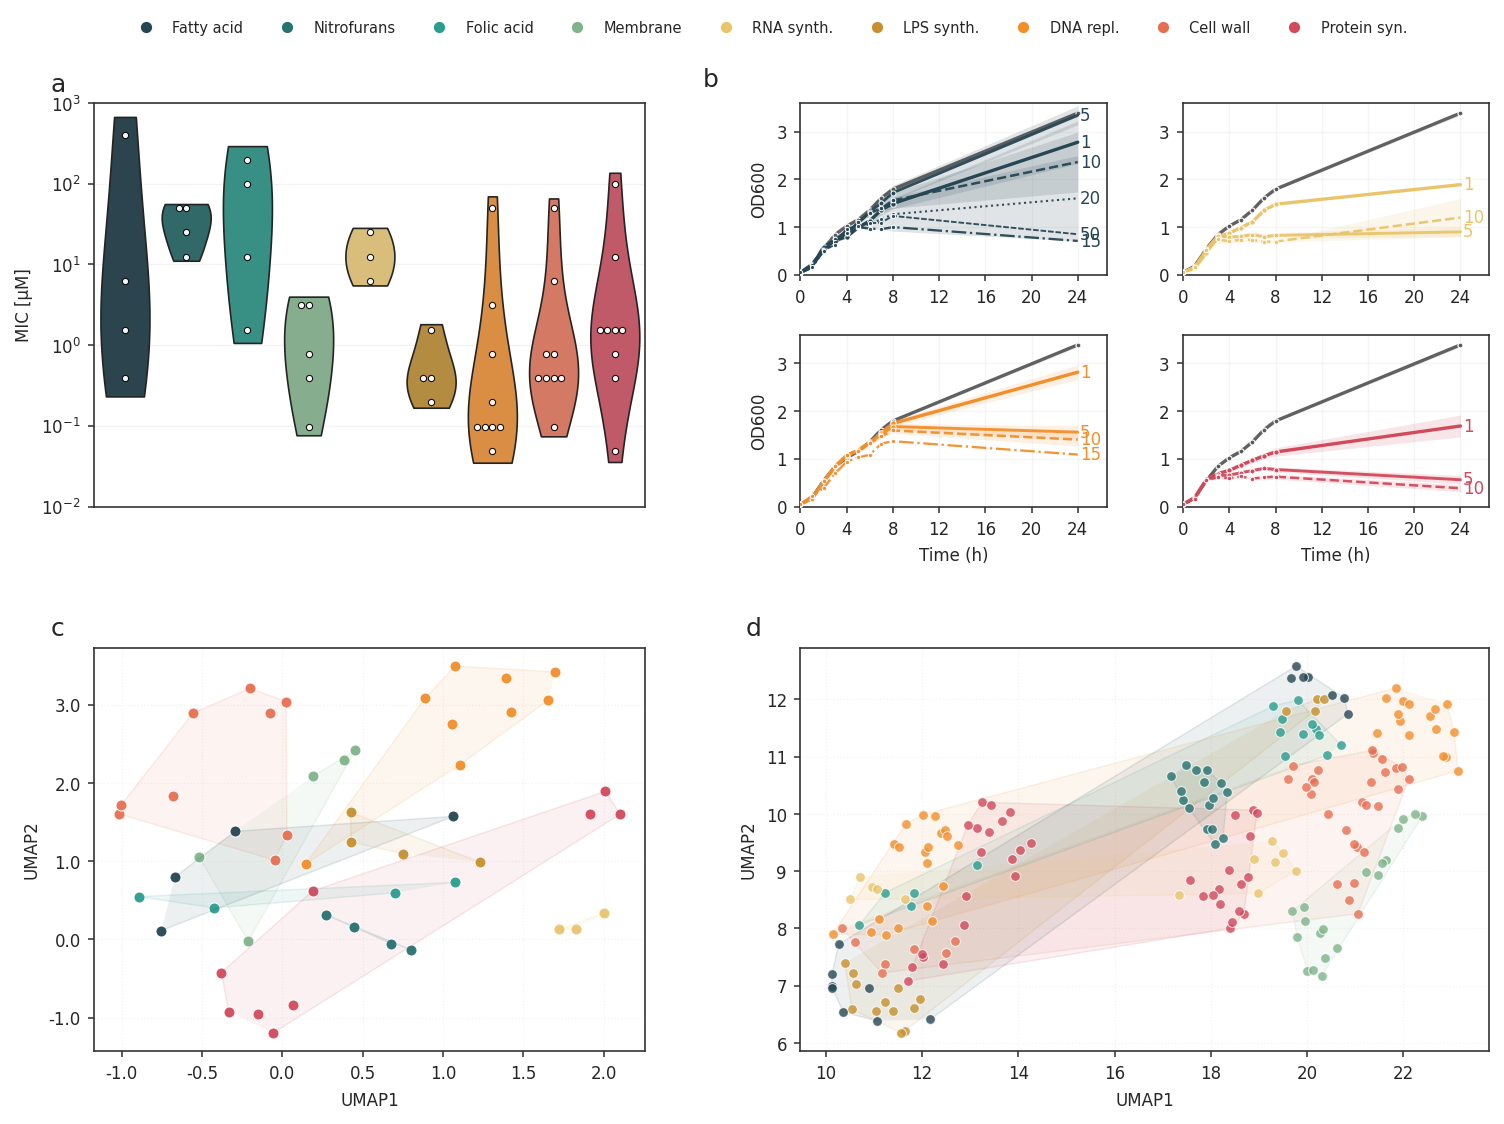

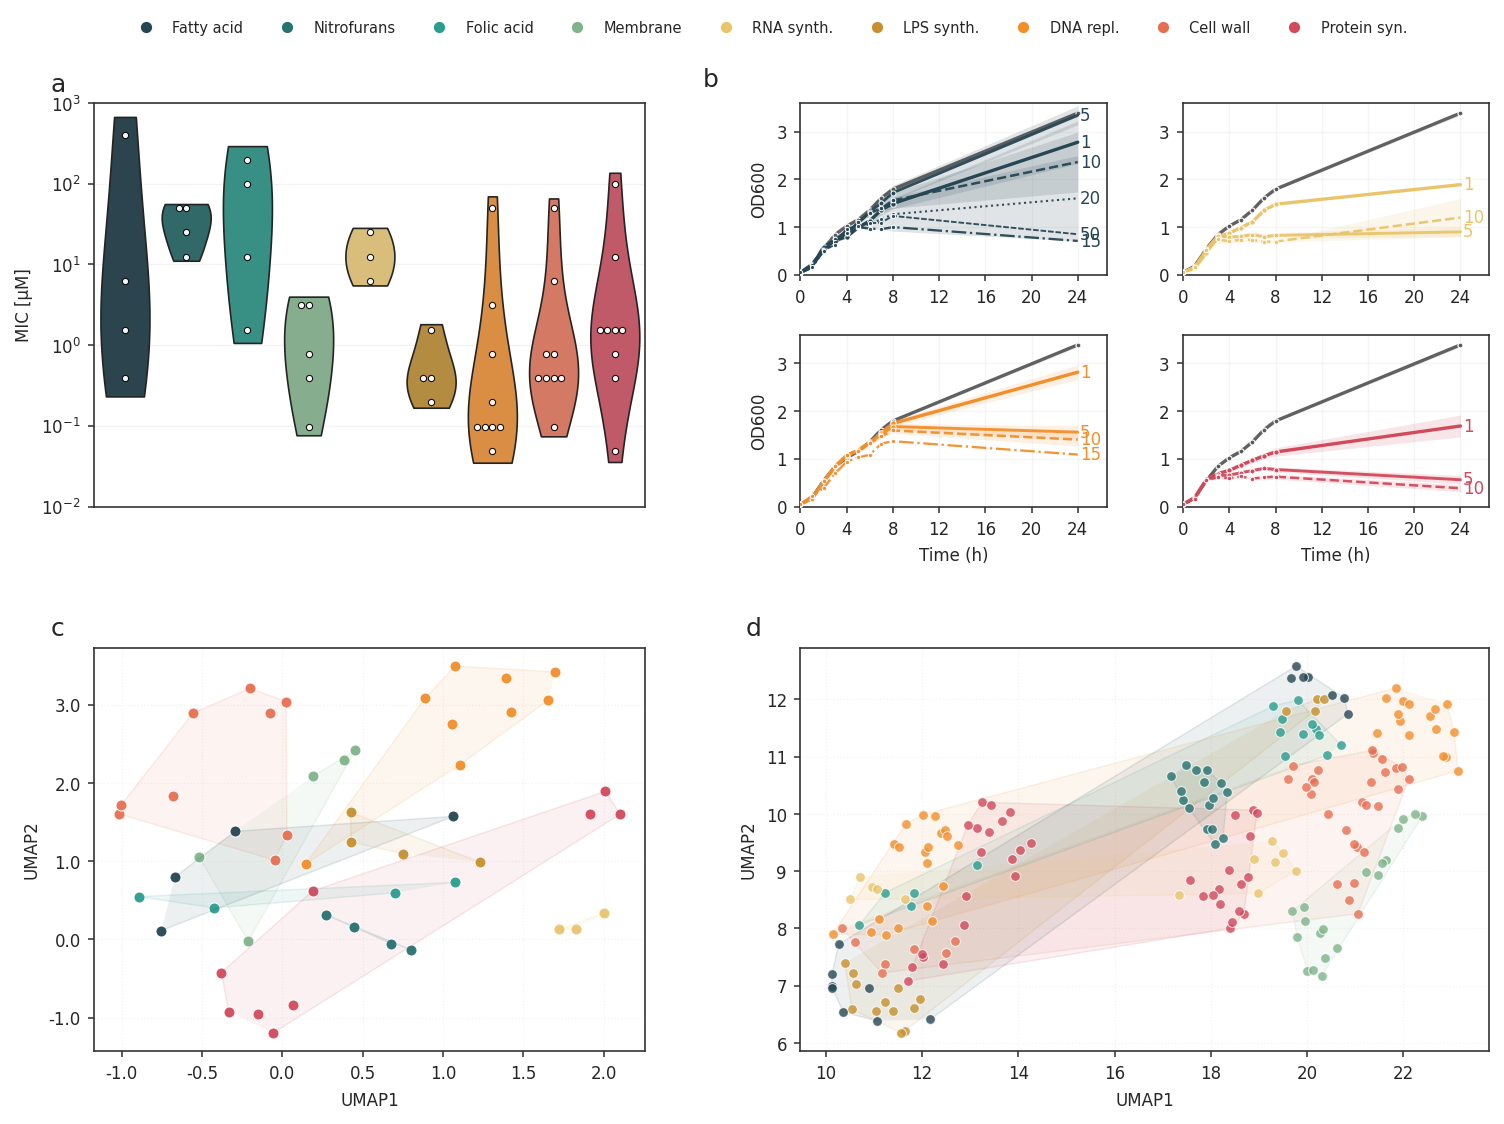

In [9]:
# --- Build combined Figure 2 ---
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1.0, 1.25],
    height_ratios=[1.0, 1.0],
    wspace=0.25,
    hspace=0.35,
)

ax_a = fig.add_subplot(gs[0, 0])
gs_b = gs[0, 1].subgridspec(2, 2, wspace=0.25, hspace=0.35)
ax_b = np.array([
    [fig.add_subplot(gs_b[0, 0]), fig.add_subplot(gs_b[0, 1])],
    [fig.add_subplot(gs_b[1, 0]), fig.add_subplot(gs_b[1, 1])],
])
ax_c = fig.add_subplot(gs[1, 0])
ax_d = fig.add_subplot(gs[1, 1])

plot_mic_by_moa_violin_ax(ax_a, mic_data, y_labels, ecfp_unique=ecfp_unique, label_col=None)

moas_b = [m for m in MOA_ORDER_FIXED if m in ['DNA repl.', 'Fatty acid', 'Protein syn.', 'RNA synth.']]
handles_b = plot_growth_facets_axes(ax_b, growth_clean_long, moas_to_show=moas_b)

plot_ecfp_embedding_ax(ax_c, ecfp_unique, y_labels, label_col=None, use_umap=True, draw_hulls=True)
plot_proteomics_embedding_ax(ax_d, proteomics_data, y_labels, replicate_mode='all', use_umap=True, draw_hulls=True)

# Panel labels
ax_a.text(-0.08, 1.03, 'a', transform=ax_a.transAxes, fontsize=12)
ax_b[0, 0].text(-0.32, 1.10, 'b', transform=ax_b[0, 0].transAxes, fontsize=12)
ax_c.text(-0.08, 1.03, 'c', transform=ax_c.transAxes, fontsize=12)
ax_d.text(-0.08, 1.03, 'd', transform=ax_d.transAxes, fontsize=12)

# Global MoA legend (top row)
legend_handles = []
legend_labels = []
for moa in MOA_ORDER_FIXED:
    if moa not in MOA_COLOR_MAP:
        continue
    legend_handles.append(
        Line2D([0], [0], marker='o', color='none', markerfacecolor=MOA_COLOR_MAP[moa],
               markeredgecolor='white', markeredgewidth=0.6, markersize=6)
    )
    legend_labels.append(moa)

fig.legend(
    legend_handles,
    legend_labels,
    loc='upper center',
    ncol=len(legend_labels),
    frameon=False,
    bbox_to_anchor=(0.5, .98),
)

fig.tight_layout()
fig.subplots_adjust(top=0.90)

fig


In [10]:
# --- Save combined figure ---
save_dir = set_save_dir(PROJECT_ROOT, 'figure2')
save_figure(fig, 'figure2_combined')
print(f'Saved to: {save_dir}')


Saved to: /mnt/nas/PhD/Code/Ms_paint/code_repository/images/figure2
